# Ten-Day VaR of a Delta-Hedged Short Put
## The square-root-of-time rule versus time aggregation with daily rebalancing

The portfolio is short 100 European puts ($\kappa=170$, $T=0.292$) and delta-hedged
with the stock in a Black–Scholes market, the hedge being reset every trading day
and financed through a money-market account. This notebook estimates the 95%
ten-day Value at Risk twice: by simulating the **one-day** loss (40,000 runs) and
scaling it by $\sqrt{10}$, and by simulating the whole **ten-day** self-financing
strategy path by path (40,000 paths). It then explains why the two answers differ.

**Model.** Under the physical measure $dS_t/S_t=\mu\,dt+\sigma\,dW_t$, so the daily
log returns $X_{t+j\Delta}=\ln(S_{t+j\Delta}/S_{t+(j-1)\Delta})$ are i.i.d.
$N\bigl((\mu-\tfrac12\sigma^2)\Delta,\ \sigma^2\Delta\bigr)$. $P^{BS}(t,s)$ is the
Black–Scholes **put** price (the sheet's "call price" is a slip: the hedge ratio it
defines, $h_t=\partial_sP^{BS}(t,S_t)$, is a put delta, and the position is in puts).

**Portfolio.** At $T_0=t$, with $Y_{T_0}=0$ in the bank,
$Y^{\text{new}}_{T_0}=-h_{T_0}S_{T_0}$ and $V_{T_0}=Y^{\text{new}}_{T_0}+h_{T_0}S_{T_0}-P^{BS}(T_0,S_{T_0})$.
Over each day $[T_{j-1},T_j]$ the share holding $h_{T_{j-1}}$ is fixed and the bank
grows at $r$:
$V_{T_j}=h_{T_{j-1}}S_{T_j}+Y^{\text{new}}_{T_{j-1}}e^{r\Delta}-P^{BS}(T_j,S_{T_j})$.
At the start of the next day the hedge is reset to $h_{T_j}=\partial_sP^{BS}(T_j,S_{T_j})$
and the bank absorbs the trade: $Y^{\text{new}}_{T_j}=Y^{\text{new}}_{T_{j-1}}e^{r\Delta}+(h_{T_{j-1}}-h_{T_j})S_{T_j}$.
The $J$-day loss is $L_{t+J\Delta}=-(V_{T_J}-V_{T_0})$, and for $n$ simulated losses
$\widehat{\mathrm{VaR}}_\alpha=\ell_{(\lceil n\alpha\rceil)}$.

---
## 1. Imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import scipy
from scipy.stats import norm, chi2, skew
from scipy.optimize import brentq, minimize_scalar
import matplotlib
import matplotlib.pyplot as plt

print("python     ", sys.version.split()[0])
print("numpy      ", np.__version__)
print("scipy      ", scipy.__version__)
print("matplotlib ", matplotlib.__version__)

python      3.13.16
numpy       2.5.3
scipy       1.18.1
matplotlib  3.11.2


---
## 2. Parameters

| Symbol | Meaning | Value |
|---|---|---|
| $\alpha$ | VaR confidence level | 0.95 |
| $t$ | today | 0 |
| $\Delta$ | one trading day | $1/252$ |
| $J$ | horizon in days | 10 |
| $T$ | option maturity | 0.292 |
| $S_t$ | stock price | 152.51 |
| $\kappa$ | strike | 170 |
| $r$ | risk-free rate | 0.119% |
| $\sigma$ | volatility | 49.07% |
| $\mu$ | physical drift | 16.91% |
| $M$ | puts sold | 100 |
| $n$ | simulation runs (both methods) | 40,000 |

Each simulation has its own fixed seed, so re-running reproduces every number.

In [2]:
ALPHA = 0.95
T0    = 0.0
DT    = 1.0 / 252.0          # Delta
J     = 10
T_MAT = 0.292
S0    = 152.51
KAPPA = 170.0
R     = 0.00119
SIGMA = 0.4907
MU    = 0.1691
M_OPT = 100
N_SIM = 40_000
SEED_1D, SEED_10D = 731, 732

M_X = (MU - 0.5 * SIGMA ** 2) * DT        # mean of a daily log return
S_X = SIGMA * np.sqrt(DT)                 # its standard deviation

FIG1 = Path("var_10day_distributions.png")
FIG2 = Path("var_10day_horizon_ratio.png")
C_ONE, C_TEN, C_APX = "#2a78d6", "#eb6834", "#4a3aa7"
C_INK, C_MUTE = "#0b0b0b", "#8a8a85"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 11,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.labelsize": 11, "legend.frameon": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
})
assert T_MAT - J * DT > 0, "the horizon must end before maturity"
print(f"daily log return X ~ N({M_X:.8f}, {S_X:.8f}^2)")
print(f"time to maturity: {T_MAT:.6f} today, {T_MAT - J * DT:.6f} after {J} days")

daily log return X ~ N(0.00019328, 0.03091119^2)
time to maturity: 0.292000 today, 0.252317 after 10 days


---
## 3. Black–Scholes put price and delta

$$P^{BS}(t,s)=\kappa e^{-r(T-t)}N(-d_2)-s\,N(-d_1),\qquad
d_{1,2}=\frac{\ln(s/\kappa)+(r\pm\tfrac12\sigma^2)(T-t)}{\sigma\sqrt{T-t}},$$

$$h(t,s)=\partial_sP^{BS}(t,s)=N(d_1)-1,\qquad
\Gamma(t,s)=\partial_{ss}P^{BS}(t,s)=\frac{\varphi(d_1)}{s\,\sigma\sqrt{T-t}} .$$

Gamma is not needed by either VaR method; it is used only in section 7 to explain
the difference between them.

In [3]:
def _d1d2(t, s):
    tau = T_MAT - t
    d1 = (np.log(s / KAPPA) + (R + 0.5 * SIGMA ** 2) * tau) / (SIGMA * np.sqrt(tau))
    return d1, d1 - SIGMA * np.sqrt(tau), tau


def put_price(t, s):
    d1, d2, tau = _d1d2(t, s)
    return KAPPA * np.exp(-R * tau) * norm.cdf(-d2) - s * norm.cdf(-d1)


def put_delta(t, s):
    return norm.cdf(_d1d2(t, s)[0]) - 1.0


def put_gamma(t, s):
    d1, _, tau = _d1d2(t, s)
    return norm.pdf(d1) / (s * SIGMA * np.sqrt(tau))


P0, H0, G0 = float(put_price(T0, S0)), float(put_delta(T0, S0)), float(put_gamma(T0, S0))
print(f"P^BS(t, S_t) = {P0:.6f}     h_t = {H0:.6f}     Gamma_t = {G0:.6f}")

# checks: put-call parity, and the delta is the derivative of the price
d1, d2, tau = _d1d2(T0, S0)
call = S0 * norm.cdf(d1) - KAPPA * np.exp(-R * tau) * norm.cdf(d2)
assert abs((call - P0) - (S0 - KAPPA * np.exp(-R * tau))) < 1e-10
eps = 1e-4
assert abs((put_price(T0, S0 + eps) - put_price(T0, S0 - eps)) / (2 * eps) - H0) < 1e-7
print("put-call parity and finite-difference delta: OK")

P^BS(t, S_t) = 27.107729     h_t = -0.608555     Gamma_t = 0.009498
put-call parity and finite-difference delta: OK


---
## 4. One-day VaR and the square-root-of-time rule — Question 1

Over $[t,t+\Delta]$, with $S_{t+\Delta}=S_te^{x}$, the loss of the 100-put position is

$$\ell_{[t]}(x)=M\Bigl(P^{BS}(t+\Delta,S_te^{x})-P^{BS}(t,S_t)-h_tS_t\bigl(e^{x}-e^{r\Delta}\bigr)\Bigr),$$

(derivation in the handwritten part). Simulate $n=40{,}000$ daily log returns, take
the 38,000th smallest loss, and multiply by $\sqrt{10}$.

### Pseudocode — one-day VaR, then square-root-of-time

```
INPUT : model and option parameters, M = 100, n = 40,000, alpha, a seed
OUTPUT: one-day VaR and the square-root-of-time ten-day VaR

1  P0 <- put price at (t, S_t);  h <- put delta at (t, S_t)
2  bank after hedging: Y_new <- 0 - h * S_t ;   value V_t = Y_new + h*S_t - P0 = -P0
3  fix the seed; draw x_1 ... x_n i.i.d. N((mu - sigma^2/2) Delta, sigma^2 Delta)
4  for each x_k:
5        S1 <- S_t * exp(x_k)
6        V1 <- h * S1 + Y_new * exp(r Delta) - (put price at t+Delta and S1)
7        loss_k <- - M * (V1 - V_t)
8  VaR_1 <- the ceil(n * alpha)-th smallest loss            (n alpha = 38,000)
9  VaR_10 (rule) <- sqrt(10) * VaR_1
```

In [4]:
def loss_one_day(x):
    """Full one-day loss of the hedged position (M puts) as a function of the log return x."""
    x = np.asarray(x, float)
    s1 = S0 * np.exp(x)
    y_new = -H0 * S0
    v0 = y_new + H0 * S0 - P0                      # = -P0
    v1 = H0 * s1 + y_new * np.exp(R * DT) - put_price(T0 + DT, s1)
    return -M_OPT * (v1 - v0)


def emp_var(losses, alpha=ALPHA):
    l = np.sort(np.asarray(losses, float))
    k = int(np.ceil(round(len(l) * alpha, 9)))
    return float(l[k - 1]), k


def quantile_band(losses, alpha=ALPHA, z=1.959964):
    """Distribution-free ~95% band for the true alpha-quantile, from order statistics."""
    l = np.sort(losses); n = len(l); half = z * np.sqrt(n * alpha * (1 - alpha))
    return float(l[int(np.floor(n * alpha - half)) - 1]), float(l[int(np.ceil(n * alpha + half)) - 1])


rng1 = np.random.default_rng(SEED_1D)
X1 = rng1.normal(M_X, S_X, N_SIM)
L1 = loss_one_day(X1)
VAR_1D, k1 = emp_var(L1)
VAR_SQRT = np.sqrt(J) * VAR_1D
b1 = quantile_band(L1)

print(f"ONE-DAY LOSS, {N_SIM:,} runs (seed {SEED_1D})")
print(f"  mean {L1.mean():.4f}   sd {L1.std(ddof=1):.4f}   min {L1.min():.4f}   max {L1.max():.4f}")
print(f"  VaR_0.95 (one day) = {VAR_1D:.4f}     order statistic k = {k1:,}"
      f"     order-statistic 95% band [{b1[0]:.2f}, {b1[1]:.2f}]")
print(f"  ten-day VaR by the square-root-of-time rule = sqrt(10) x {VAR_1D:.4f} = {VAR_SQRT:.4f}")

ONE-DAY LOSS, 40,000 runs (seed 731)
  mean 0.0229   sd 14.9944   min -10.5825   max 234.9152
  VaR_0.95 (one day) = 29.9398     order statistic k = 38,000     order-statistic 95% band [29.32, 30.85]
  ten-day VaR by the square-root-of-time rule = sqrt(10) x 29.9398 = 94.6780


### A check that needs no simulation

The one-day loss is a function of a single normal variable and is U-shaped in $x$
(the position is short gamma), so $\{\ell_{[t]}(X)\le\ell\}=\{x_-(\ell)\le X\le x_+(\ell)\}$
and $F(\ell)=\Phi\bigl((x_+-m)/s\bigr)-\Phi\bigl((x_--m)/s\bigr)$, the two roots found
numerically. Solving $F(\ell)=0.95$ gives the one-day VaR without sampling error,
which tells us how much of the final comparison could be simulation noise.

In [5]:
res = minimize_scalar(lambda x: float(loss_one_day(x)), bounds=(-0.2, 0.2), method="bounded",
                      options={"xatol": 1e-12})
X_MIN, L_MIN = float(res.x), float(res.fun)


def cdf_one_day(level):
    if level <= L_MIN:
        return 0.0
    xl = brentq(lambda x: float(loss_one_day(x)) - level, X_MIN - 1.0, X_MIN)
    xr = brentq(lambda x: float(loss_one_day(x)) - level, X_MIN, X_MIN + 1.0)
    return float(norm.cdf((xr - M_X) / S_X) - norm.cdf((xl - M_X) / S_X))


VAR_1D_EXACT = brentq(lambda v: cdf_one_day(v) - ALPHA, L_MIN + 1e-9, 1000.0)
print(f"loss minimised at x = {X_MIN:.6f} (value {L_MIN:.4f}): the U-shape of a short-gamma book")
print(f"exact one-day VaR_0.95       = {VAR_1D_EXACT:.4f}   (simulated {VAR_1D:.4f})")
print(f"exact sqrt(10) x one-day VaR = {np.sqrt(J) * VAR_1D_EXACT:.4f}   (simulated {VAR_SQRT:.4f})")

# cross-check with the lecture's call example: by put-call parity a delta-hedged short put is a
# delta-hedged short call plus a riskless position, so the two one-day losses differ by a constant
def loss_one_day_call(x):
    s1 = S0 * np.exp(np.asarray(x, float))
    d1_, d2_, tau_ = _d1d2(T0, S0)
    c0 = S0 * norm.cdf(d1_) - KAPPA * np.exp(-R * tau_) * norm.cdf(d2_)
    hc = norm.cdf(d1_)
    d1n, d2n, taun = _d1d2(T0 + DT, s1)
    c1 = s1 * norm.cdf(d1n) - KAPPA * np.exp(-R * taun) * norm.cdf(d2n)
    return -M_OPT * ((hc * s1 - hc * S0 * np.exp(R * DT) - c1) - (-c0))

gap_pc = loss_one_day(X1) - loss_one_day_call(X1)
const_pc = -M_OPT * (np.exp(R * DT) - 1) * (S0 - KAPPA * np.exp(-R * T_MAT))
print(f"put loss - call loss: between {gap_pc.min():.6f} and {gap_pc.max():.6f}"
      f"  (constant -M(e^(r Delta)-1)(S_t - K e^(-rT)) = {const_pc:.6f})")

loss minimised at x = 0.000981 (value -10.5825): the U-shape of a short-gamma book
exact one-day VaR_0.95       = 30.0461   (simulated 29.9398)
exact sqrt(10) x one-day VaR = 95.0142   (simulated 94.6780)
put loss - call loss: between 0.008231 and 0.008231  (constant -M(e^(r Delta)-1)(S_t - K e^(-rT)) = 0.008231)


---
## 5. Ten-day VaR by time aggregation — Question 2

Simulate the whole ten-day path of the self-financing strategy: each day the stock
moves, the bank accrues interest, the position is marked to market, and — except
after the last day — the hedge is reset to the new delta, the share trade being paid
for out of (or into) the bank. Rebalancing moves value between stock and bank but
creates none, which the code checks on every path.

### Pseudocode — ten-day time aggregation

```
INPUT : model and option parameters, M, J = 10, n = 40,000, alpha, a seed
OUTPUT: n ten-day losses and the ten-day VaR

 1  fix the seed; draw an n x J matrix of i.i.d. daily log returns
 2  on every path:  S <- S_t ;  h <- put delta at (t, S_t) ;  Y_new <- -h * S_t
 3                  V0 <- Y_new + h * S - (put price at t)          ( = -P0 )
 4  for j = 1 ... J:
 5        S <- S * exp(x_j)                                 the day's move
 6        Y <- Y_new * exp(r Delta)                          interest on the bank
 7        V_j <- h * S + Y - (put price at T_j and S)        close of day j
 8        if j < J:                                          rebalance for day j+1
 9              h_new <- put delta at (T_j, S)
10              Y_new <- Y + (h - h_new) * S                 bank pays for the share trade
11              check: h_new * S + Y_new - put price = V_j   (self-financing)
12              h <- h_new
13  ten-day loss <- - M * (V_J - V0)                         ( = sum of the daily losses )
14  VaR_10 <- the ceil(n * alpha)-th smallest ten-day loss
```

In [6]:
def simulate_strategy(x, rebalance=True):
    """Run the self-financing hedge along each row of x (n paths x J days).
    Returns the n x J matrix of daily losses (M puts); row sums are the J-day losses."""
    n, jmax = x.shape
    s = np.full(n, S0)
    h = np.full(n, H0)
    y_new = -h * s
    v_prev = y_new + h * s - put_price(T0, s)
    daily = np.empty((n, jmax))
    worst_gap = 0.0
    for j in range(1, jmax + 1):
        tj = T0 + j * DT
        s = s * np.exp(x[:, j - 1])
        y = y_new * np.exp(R * DT)
        p = put_price(tj, s)
        v = h * s + y - p
        daily[:, j - 1] = -M_OPT * (v - v_prev)
        if rebalance and j < jmax:
            h_new = put_delta(tj, s)
            y_new = y + (h - h_new) * s
            worst_gap = max(worst_gap, float(np.max(np.abs(h_new * s + y_new - p - v))))
            h = h_new
        else:
            y_new = y
        v_prev = v
    return daily, worst_gap


rng10 = np.random.default_rng(SEED_10D)
X10 = rng10.normal(M_X, S_X, (N_SIM, J))
DAILY, gap = simulate_strategy(X10)
L10 = DAILY.sum(axis=1)
VAR_10D, k10 = emp_var(L10)
b10 = quantile_band(L10)

print(f"TEN-DAY LOSS WITH DAILY REBALANCING, {N_SIM:,} paths (seed {SEED_10D})")
print(f"  largest value change caused by any rebalancing trade: {gap:.2e}  (self-financing)")
print(f"  mean {L10.mean():.4f}   sd {L10.std(ddof=1):.4f}   min {L10.min():.4f}   max {L10.max():.4f}")
print(f"  VaR_0.95 (ten days) = {VAR_10D:.4f}     order statistic k = {k10:,}"
      f"     order-statistic 95% band [{b10[0]:.2f}, {b10[1]:.2f}]")
assert gap < 1e-8

TEN-DAY LOSS WITH DAILY REBALANCING, 40,000 paths (seed 732)
  largest value change caused by any rebalancing trade: 2.13e-14  (self-financing)
  mean 0.6992   sd 48.3881   min -108.8646   max 306.3127
  VaR_0.95 (ten days) = 89.5167     order statistic k = 38,000     order-statistic 95% band [87.88, 91.34]


---
## 6. The two estimates side by side — Question 3

In [7]:
diff = VAR_SQRT - VAR_10D
print(f"{'':<46}{'VaR_0.95':>10}")
print(f"{'sqrt(10) x simulated one-day VaR (Q1)':<46}{VAR_SQRT:>10.2f}")
print(f"{'sqrt(10) x exact one-day VaR (check)':<46}{np.sqrt(J) * VAR_1D_EXACT:>10.2f}")
print(f"{'ten-day time aggregation, rebalanced (Q2)':<46}{VAR_10D:>10.2f}")
print(f"\nrule minus time aggregation = {diff:.2f}, i.e. the rule is {diff / VAR_10D:.1%} higher")
print(f"ratio  time aggregation / rule = {VAR_10D / VAR_SQRT:.4f}")
print(f"\nthe ten-day order-statistic band [{b10[0]:.2f}, {b10[1]:.2f}] excludes the rule's value: "
      f"{not (b10[0] <= VAR_SQRT <= b10[1])}")

                                                VaR_0.95
sqrt(10) x simulated one-day VaR (Q1)              94.68
sqrt(10) x exact one-day VaR (check)               95.01
ten-day time aggregation, rebalanced (Q2)          89.52

rule minus time aggregation = 5.16, i.e. the rule is 5.8% higher
ratio  time aggregation / rule = 0.9455

the ten-day order-statistic band [87.88, 91.34] excludes the rule's value: True


---
## 7. Why they differ

The square-root-of-time rule is exact when the $J$-day loss is the sum of $J$
i.i.d. **normal** daily losses with mean zero (lecture: linearized losses of a
constant equity position). Then both the standard deviation and every quantile
scale by $\sqrt J$. Here the daily losses are close to independent and have mean
near zero, so the standard deviation does scale by about $\sqrt{10}$ — but they are
**not normal**. The hedge removes the first-order exposure, and what is left is
gamma. A second-order expansion of the price together with the Black–Scholes PDE
(derivation in the handwritten part) gives, for each day,

$$L_j\;\approx\;c_j\,(Z_j^2-1),\qquad c_j=\tfrac12M\,\Gamma_{T_{j-1}}S_{T_{j-1}}^2\sigma^2\Delta,\qquad Z_j\ \text{i.i.d.}\ N(0,1).$$

A daily loss is therefore a scaled, centred $\chi^2_1$: bounded below by about $-c$
(time decay earned on a quiet day) and strongly right-skewed. With $c_j\approx c$:

* one day: $\mathrm{VaR}_{0.95}\approx c\,(\chi^2_{1,0.95}-1)=2.841\,c$;
* ten days: $L\approx c(\chi^2_{10}-10)$, so $\mathrm{VaR}_{0.95}\approx c\,(\chi^2_{10,0.95}-10)=8.307\,c$;
* the rule instead gives $\sqrt{10}\times2.841\,c=8.985\,c$, about 8% too high.

Summing ten independent skewed losses partly averages the skewness away
(skewness falls by $\sqrt{10}$, from $\sqrt8\approx2.83$ to $\approx0.89$), so the
95% quantile, measured in standard deviations, falls from $2.84/\sqrt2=2.01$ to
$8.31/\sqrt{20}=1.86$. The rule keeps the one-day shape and so overstates the
ten-day tail. The cells below check each step of that argument on the simulated
losses.

In [8]:
C_DG = 0.5 * M_OPT * G0 * S0 ** 2 * SIGMA ** 2 * DT
q1, q10 = chi2.ppf(ALPHA, 1) - 1, chi2.ppf(ALPHA, J) - J
print(f"c = (1/2) M Gamma S^2 sigma^2 Delta = {C_DG:.4f}")
print(f"  chi^2_1(0.95) - 1   = {q1:.4f}    ->  one-day VaR  approx {C_DG * q1:7.2f}   (simulated {VAR_1D:.2f})")
print(f"  chi^2_10(0.95) - 10 = {q10:.4f}    ->  ten-day VaR  approx {C_DG * q10:7.2f}   (simulated {VAR_10D:.2f})")
print(f"  sqrt(10) x one-day approx                 = {np.sqrt(J) * C_DG * q1:7.2f}   (simulated {VAR_SQRT:.2f})")
print(f"  approximate ratio ten-day / rule = {q10 / (np.sqrt(J) * q1):.4f}   (simulated {VAR_10D / VAR_SQRT:.4f})")
print(f"  lower bound of a daily loss approx -c = {-C_DG:.2f}   (exact minimum {L_MIN:.2f})")

print("\nMOMENTS OF THE SIMULATED LOSSES")
print(f"  {'':<26}{'mean':>9}{'sd':>9}{'skewness':>10}{'VaR/sd':>9}")
for lab, L in (("one day", L1), ("ten days, rebalanced", L10)):
    print(f"  {lab:<26}{L.mean():>9.3f}{L.std(ddof=1):>9.3f}{skew(L):>10.3f}"
          f"{emp_var(L)[0] / L.std(ddof=1):>9.3f}")
print(f"  {'chi^2 approximation':<26}{'':>9}{'':>9}{np.sqrt(8):>7.3f} ->{np.sqrt(8 / J):.3f}"
      f"{q1 / np.sqrt(2):>6.3f} ->{q10 / np.sqrt(2 * J):.3f}")
print(f"\n  sd ratio ten-day / one-day = {L10.std(ddof=1) / L1.std(ddof=1):.4f}   (sqrt(10) = {np.sqrt(J):.4f})")
corr = np.corrcoef(DAILY.T)
off = corr[~np.eye(J, dtype=bool)]
print(f"  correlation between different days' losses: largest |rho| = {np.abs(off).max():.4f}")

c = (1/2) M Gamma S^2 sigma^2 Delta = 10.5539
  chi^2_1(0.95) - 1   = 2.8415    ->  one-day VaR  approx   29.99   (simulated 29.94)
  chi^2_10(0.95) - 10 = 8.3070    ->  ten-day VaR  approx   87.67   (simulated 89.52)
  sqrt(10) x one-day approx                 =   94.83   (simulated 94.68)
  approximate ratio ten-day / rule = 0.9245   (simulated 0.9455)
  lower bound of a daily loss approx -c = -10.55   (exact minimum -10.58)

MOMENTS OF THE SIMULATED LOSSES
                                 mean       sd  skewness   VaR/sd


  one day                       0.023   14.994     2.873    1.997


  ten days, rebalanced          0.699   48.388     0.891    1.850
  chi^2 approximation                           2.828 ->0.894 2.009 ->1.858

  sd ratio ten-day / one-day = 3.2271   (sqrt(10) = 3.1623)
  correlation between different days' losses: largest |rho| = 0.0147


### Two more points of reference

* **The approximation explains most, not all, of the gap.** Along a path the
  coefficient $c_j$ moves with $\Gamma_{T_{j-1}}S^2_{T_{j-1}}$, which adds a little
  dispersion and lifts the simulated ten-day VaR slightly above $8.307\,c$.
* **Without rebalancing the picture reverses.** If the day-one hedge were simply held
  for ten days, the loss would be $\approx\tfrac12M\Gamma S^2\bigl(\sum_jX_j\bigr)^2$:
  quadratic in a move whose variance is ten times larger, so the VaR grows roughly
  like $J$, not $\sqrt J$. The cell below simulates that case on the same paths. It is
  not what the assignment asks for; it shows that the rule's error depends on the
  trading strategy, not only on the risk factor.

In [9]:
DAILY_NR, _ = simulate_strategy(X10, rebalance=False)
L10_NR = DAILY_NR.sum(axis=1)
VAR_10D_NR = emp_var(L10_NR)[0]
print(f"ten-day VaR_0.95, hedge held fixed for ten days (same paths): {VAR_10D_NR:.2f}")
print(f"  = {VAR_10D_NR / VAR_1D:.2f} x one-day VaR    (sqrt(10) = {np.sqrt(J):.2f}, 10 = {J})")

ten-day VaR_0.95, hedge held fixed for ten days (same paths): 304.86
  = 10.18 x one-day VaR    (sqrt(10) = 3.16, 10 = 10)


---
## 8. Figures

### Pseudocode — distribution figure

```
1  histogram sqrt(10) x (one-day losses): the ten-day law the rule implicitly assumes
2  histogram the simulated ten-day losses with rebalancing, on the same bins
3  mark both VaR estimates; label them directly; save
```

### Pseudocode — horizon figure

```
1  for J' = 1 ... 10: J'-day losses = sum of the first J' daily losses on each path
2  ratio(J') = VaR of the J'-day losses / (sqrt(J') x exact one-day VaR)   (+ order-statistic band)
3  plot the ratio with its chi-square approximation (chi2_J'(0.95) - J') / (sqrt(J') (chi2_1(0.95) - 1))
4  draw the reference line 1 (where the rule would be exact); save
```

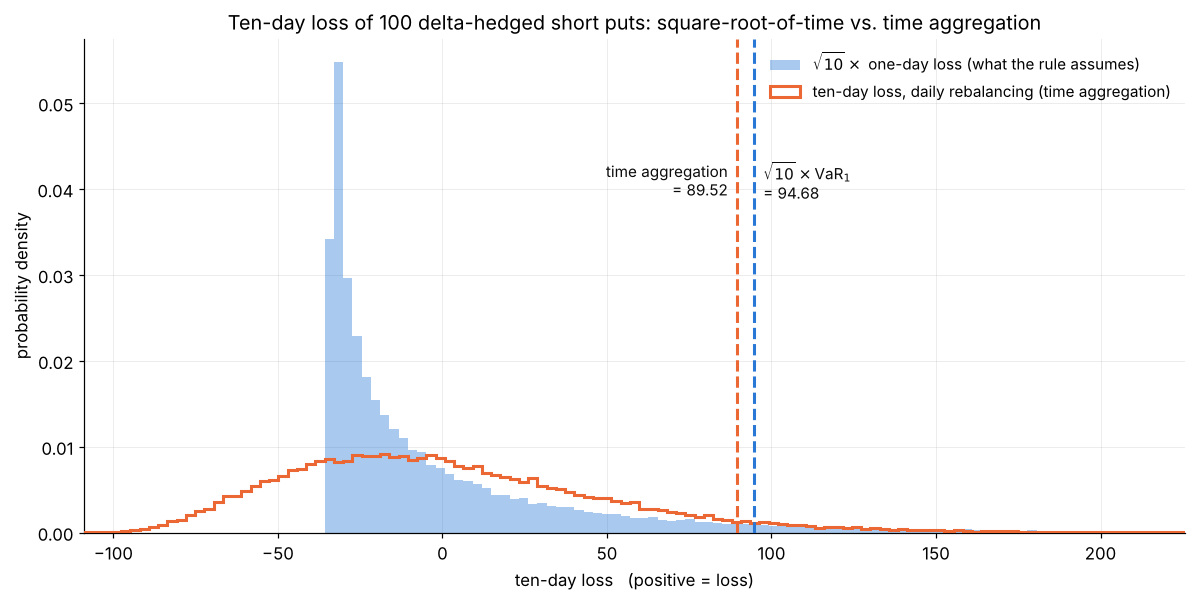

saved var_10day_distributions.png  (x-axis cut at the 99.7th percentile)


In [10]:
fig, ax = plt.subplots(figsize=(11, 5.6))
scaled = np.sqrt(J) * L1
lo, hi = min(scaled.min(), L10.min()), np.percentile(np.concatenate([scaled, L10]), 99.7)
bins = np.linspace(lo, hi, 120)
ax.hist(scaled, bins=bins, density=True, color=C_ONE, alpha=0.40, zorder=2,
        label=r"$\sqrt{10}\times$ one-day loss (what the rule assumes)")
ax.hist(L10, bins=bins, density=True, histtype="step", color=C_TEN, lw=2.0, zorder=3,
        label="ten-day loss, daily rebalancing (time aggregation)")
ytop = ax.get_ylim()[1]
for v, c, lab, side in ((VAR_SQRT, C_ONE, r"$\sqrt{10}\times$VaR$_1$", +1), (VAR_10D, C_TEN, "time aggregation", -1)):
    ax.axvline(v, color=c, lw=2.0, ls="--", zorder=4)
    ax.annotate(f"{lab}\n= {v:.2f}", xy=(v, ytop * 0.75), xytext=(6 * side, 0), textcoords="offset points",
                fontsize=10, color=C_INK, va="top", ha="left" if side > 0 else "right")
ax.set_xlim(lo, hi)
ax.set_title("Ten-day loss of 100 delta-hedged short puts: square-root-of-time vs. time aggregation")
ax.set_xlabel("ten-day loss   (positive = loss)")
ax.set_ylabel("probability density")
ax.legend(loc="upper right", fontsize=10)
fig.tight_layout()
fig.savefig(FIG1, bbox_inches="tight")
plt.show()
print(f"saved {FIG1}  (x-axis cut at the 99.7th percentile)")

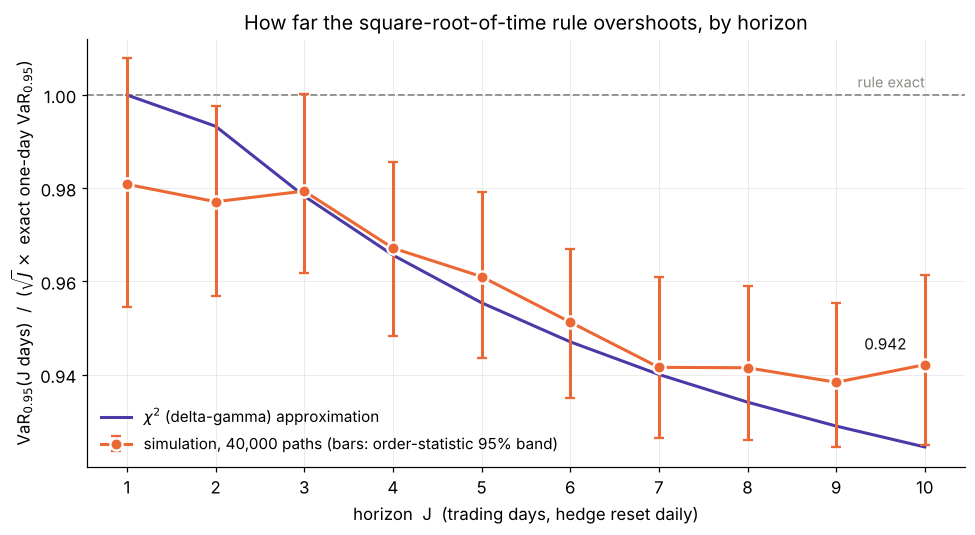

J      simulated   chi^2 approx
1         0.9808        1.0000
2         0.9771        0.9933
3         0.9794        0.9783
4         0.9672        0.9657
5         0.9610        0.9554
6         0.9513        0.9471
7         0.9416        0.9401
8         0.9415        0.9341
9         0.9384        0.9290
10        0.9421        0.9245


In [11]:
cum = np.cumsum(DAILY, axis=1)
horizons = np.arange(1, J + 1)
den = np.sqrt(horizons) * VAR_1D_EXACT                      # noise-free denominator
var_J = np.array([emp_var(cum[:, jj - 1])[0] for jj in horizons])
band_J = np.array([quantile_band(cum[:, jj - 1]) for jj in horizons])
ratio_mc = var_J / den
ratio_chi = np.array([(chi2.ppf(ALPHA, jj) - jj) / (np.sqrt(jj) * q1) for jj in horizons])

fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(1.0, color=C_MUTE, lw=1.2, ls="--", zorder=1)
ax.annotate("rule exact", xy=(J, 1.0), xytext=(0, 5), textcoords="offset points", ha="right",
            fontsize=9.5, color=C_MUTE)
ax.plot(horizons, ratio_chi, color=C_APX, lw=2.0, zorder=2, label=r"$\chi^2$ (delta-gamma) approximation")
ax.errorbar(horizons, ratio_mc, yerr=[ratio_mc - band_J[:, 0] / den, band_J[:, 1] / den - ratio_mc],
            color=C_TEN, lw=2.0, marker="o", ms=8, capsize=3, zorder=3, markeredgecolor="white",
            markeredgewidth=1.5, label="simulation, 40,000 paths (bars: order-statistic 95% band)")
ax.annotate(f"{ratio_mc[-1]:.3f}", xy=(J, ratio_mc[-1]), xytext=(-12, 10), textcoords="offset points",
            ha="right", fontsize=10, color=C_INK)
ax.set_xticks(horizons)
ax.set_xlabel("horizon  J  (trading days, hedge reset daily)")
ax.set_ylabel(r"VaR$_{0.95}$(J days)  /  ($\sqrt{J}\times$ exact one-day VaR$_{0.95}$)")
ax.set_title("How far the square-root-of-time rule overshoots, by horizon")
ax.legend(loc="lower left", fontsize=10)
fig.tight_layout()
fig.savefig(FIG2, bbox_inches="tight")
plt.show()
print("J      simulated   chi^2 approx")
for jj, a_, b_ in zip(horizons, ratio_mc, ratio_chi):
    print(f"{jj:<6}{a_:>10.4f}{b_:>14.4f}")

---
## 9. All numbers for the written PDF

In [12]:
line = "=" * 78
print(line); print("SUMMARY OF RESULTS"); print(line)
print(f"\n[OPTION AT t]  P = {P0:.6f}   h = {H0:.6f}   Gamma = {G0:.6f}   V_t = {-M_OPT * P0:.4f} (100 puts)")
print(f"[RISK FACTOR]  X ~ N({M_X:.8f}, {S_X:.8f}^2) per day")
print(f"\n[Q1] one-day VaR_0.95 (40,000 runs)          = {VAR_1D:.4f}   band [{b1[0]:.2f}, {b1[1]:.2f}]")
print(f"     exact one-day VaR_0.95                  = {VAR_1D_EXACT:.4f}")
print(f"     sqrt(10) x one-day VaR                  = {VAR_SQRT:.4f}   (exact: {np.sqrt(J) * VAR_1D_EXACT:.4f})")
print(f"[Q2] ten-day VaR_0.95, rebalanced (40,000)   = {VAR_10D:.4f}   band [{b10[0]:.2f}, {b10[1]:.2f}]")
print(f"[Q3] rule - aggregation = {VAR_SQRT - VAR_10D:.4f}  ({(VAR_SQRT - VAR_10D) / VAR_10D:.2%});"
      f"  ratio {VAR_10D / VAR_SQRT:.4f}")
print(f"     chi^2 approx: c = {C_DG:.4f}, VaR_1 ~ {C_DG * q1:.2f}, VaR_10 ~ {C_DG * q10:.2f},"
      f" ratio {q10 / (np.sqrt(J) * q1):.4f}")
print(f"     skewness one day {skew(L1):.3f}, ten days {skew(L10):.3f}")
print(f"     sd one day {L1.std(ddof=1):.4f}, ten days {L10.std(ddof=1):.4f}"
      f" (ratio {L10.std(ddof=1) / L1.std(ddof=1):.4f})")
print(f"     no rebalancing: ten-day VaR {VAR_10D_NR:.2f}")

SUMMARY OF RESULTS

[OPTION AT t]  P = 27.107729   h = -0.608555   Gamma = 0.009498   V_t = -2710.7729 (100 puts)
[RISK FACTOR]  X ~ N(0.00019328, 0.03091119^2) per day

[Q1] one-day VaR_0.95 (40,000 runs)          = 29.9398   band [29.32, 30.85]
     exact one-day VaR_0.95                  = 30.0461
     sqrt(10) x one-day VaR                  = 94.6780   (exact: 95.0142)
[Q2] ten-day VaR_0.95, rebalanced (40,000)   = 89.5167   band [87.88, 91.34]
[Q3] rule - aggregation = 5.1613  (5.77%);  ratio 0.9455
     chi^2 approx: c = 10.5539, VaR_1 ~ 29.99, VaR_10 ~ 87.67, ratio 0.9245
     skewness one day 2.873, ten days 0.891
     sd one day 14.9944, ten days 48.3881 (ratio 3.2271)
     no rebalancing: ten-day VaR 304.86


---
## 10. Self-checks

In [13]:
checks = []
check = lambda name, ok: checks.append((name, bool(ok)))

check("put price satisfies put-call parity", abs((call - P0) - (S0 - KAPPA * np.exp(-R * tau))) < 1e-10)
check("put delta lies in (-1, 0), so the hedge is short stock", -1 < H0 < 0)
check("V_t = -P (bank and stock offset at inception)", abs(float(-H0 * S0 + H0 * S0 - P0) + P0) < 1e-12)
check("one-day loss at x = 0 is small and negative (time decay)", -15 < float(loss_one_day(0.0)) < 0)
check("simulated one-day VaR inside its order-statistic band around the exact value",
      b1[0] <= VAR_1D_EXACT <= b1[1])
check("order statistics: k = 38,000 for both methods", k1 == 38_000 and k10 == 38_000)
check("hedged put and hedged call one-day losses differ by a constant (put-call parity)",
      np.ptp(gap_pc) < 1e-9 and abs(gap_pc[0] - const_pc) < 1e-9)
check("rebalancing is self-financing (value unchanged by every trade)", gap < 1e-8)
check("ten-day loss equals the sum of the daily losses",
      np.allclose(L10, DAILY.sum(axis=1)))
# an independent re-implementation of the ten-day value, written as V_J - V_0 directly
s_, h_, b_ = np.full(N_SIM, S0), np.full(N_SIM, H0), -H0 * S0 * np.ones(N_SIM)
for j in range(1, J + 1):
    s_ = s_ * np.exp(X10[:, j - 1]); b_ = b_ * np.exp(R * DT)
    if j < J:
        hn = put_delta(j * DT, s_); b_ = b_ - (hn - h_) * s_; h_ = hn
vJ = h_ * s_ + b_ - put_price(J * DT, s_)
check("independent re-implementation gives the same ten-day losses",
      np.allclose(-M_OPT * (vJ - (-P0)), L10, atol=1e-8))
check("the rule's value lies outside the ten-day band (difference is not simulation noise)",
      not (b10[0] <= VAR_SQRT <= b10[1]))
check("rule overstates the rebalanced ten-day VaR", VAR_SQRT > VAR_10D)
check("ten-day sd within 5% of sqrt(10) x one-day sd",
      abs(L10.std(ddof=1) / (np.sqrt(J) * L1.std(ddof=1)) - 1) < 0.05)
check("skewness falls with aggregation", skew(L10) < skew(L1))
check("figures written", FIG1.exists() and FIG2.exists())

for nm, ok in checks:
    print(f"  [{'PASS' if ok else 'FAIL'}]  {nm}")
assert all(ok for _, ok in checks), "some checks failed"
print("\nALL CHECKS PASSED")

  [PASS]  put price satisfies put-call parity
  [PASS]  put delta lies in (-1, 0), so the hedge is short stock
  [PASS]  V_t = -P (bank and stock offset at inception)
  [PASS]  one-day loss at x = 0 is small and negative (time decay)
  [PASS]  simulated one-day VaR inside its order-statistic band around the exact value
  [PASS]  order statistics: k = 38,000 for both methods
  [PASS]  hedged put and hedged call one-day losses differ by a constant (put-call parity)
  [PASS]  rebalancing is self-financing (value unchanged by every trade)
  [PASS]  ten-day loss equals the sum of the daily losses
  [PASS]  independent re-implementation gives the same ten-day losses
  [PASS]  the rule's value lies outside the ten-day band (difference is not simulation noise)
  [PASS]  rule overstates the rebalanced ten-day VaR
  [PASS]  ten-day sd within 5% of sqrt(10) x one-day sd
  [PASS]  skewness falls with aggregation
  [PASS]  figures written

ALL CHECKS PASSED
